In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
columns = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education_num",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
    "native_country",
    "income"
]

In [3]:
import pandas as pd

train_df = pd.read_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/datasets/adult.data",
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

test_df = pd.read_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/datasets/adult.test",
    names=columns,
    skiprows=1,
    skipinitialspace=True,
    na_values="?"
)

In [4]:
train_df["income"] = train_df["income"].str.replace(".", "", regex=False)
test_df["income"] = test_df["income"].str.replace(".", "", regex=False)

In [5]:
df = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

In [6]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [7]:
df.shape

(48842, 15)

In [8]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       46043 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education_num   48842 non-null  int64 
 5   marital_status  48842 non-null  object
 6   occupation      46033 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital_gain    48842 non-null  int64 
 11  capital_loss    48842 non-null  int64 
 12  hours_per_week  48842 non-null  int64 
 13  native_country  47985 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [10]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [11]:
df.isnull().sum()

,0
age,0
workclass,2799
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,2809
relationship,0
race,0
sex,0


In [12]:
categorical_missing = ["workclass", "occupation", "native_country"]

for col in categorical_missing:
    df[col] = df[col].fillna(df[col].mode()[0])

In [13]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [14]:
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

In [15]:
df["income"].value_counts()

,count
income,
0,37155
1,11687


In [16]:
categorical_cols = [
    "workclass",
    "education",
    "marital_status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native_country"
]

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    dtype=int
)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Columns: 106 entries, age to native_country_Yugoslavia
dtypes: int64(106)
memory usage: 39.5 MB


In [18]:
X = df.drop("income", axis=1)
y = df["income"]

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [21]:
print(X_train.shape)
print(X_test.shape)

(39073, 105)
(9769, 105)


##logistic regression


In [22]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [23]:
y_pred = model.predict(X_test)

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8489
Precision: 0.7390
Recall   : 0.5771
F1 Score : 0.6481


In [25]:
from sklearn.metrics import roc_auc_score

lr_auc = roc_auc_score(
    y_test,
    model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {lr_auc:.4f}")

ROC-AUC: 0.9035


In [26]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.94      0.90      7414
           1       0.74      0.58      0.65      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.76      0.78      9769
weighted avg       0.84      0.85      0.84      9769



[[6934  480]
 [ 996 1359]]


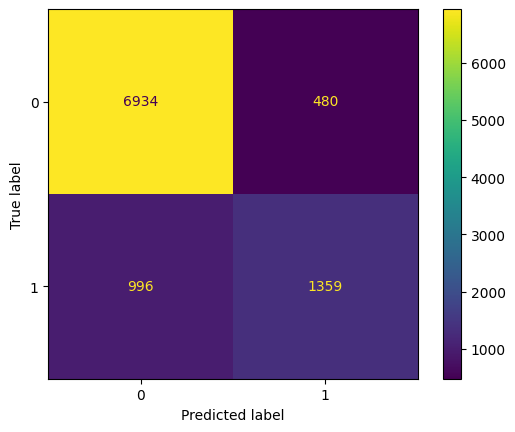

In [27]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

In [28]:
import joblib

joblib.dump(
    model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/adult_logistic_regression.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/adult_logistic_regression.pkl']

In [29]:
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy, 4),
    "Precision": round(precision, 4),
    "Recall": round(recall, 4),
    "F1 Score": round(f1, 4),
    "ROC-AUC": round(lr_auc, 4)
}

##Decision Tree

In [30]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [31]:
dt_pred = dt_model.predict(X_test)

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1 Score : {dt_f1:.4f}")

Accuracy : 0.8148
Precision: 0.6141
Recall   : 0.6238
F1 Score : 0.6189


[[6491  923]
 [ 886 1469]]


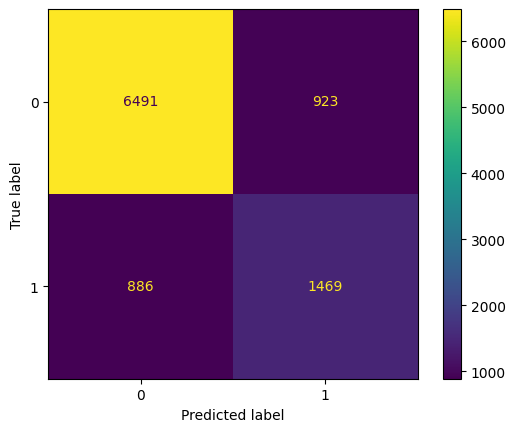

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, dt_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred
)

In [34]:
from sklearn.metrics import classification_report

print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      7414
           1       0.61      0.62      0.62      2355

    accuracy                           0.81      9769
   macro avg       0.75      0.75      0.75      9769
weighted avg       0.82      0.81      0.82      9769



In [35]:
from sklearn.metrics import roc_auc_score

dt_auc = roc_auc_score(
    y_test,
    dt_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {dt_auc:.4f}")

ROC-AUC: 0.7496


In [36]:
import joblib

joblib.dump(
    dt_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/adult_decision_tree.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/adult_decision_tree.pkl']

In [37]:
dt_results = {
    "Model": "Decision Tree",
    "Accuracy": round(dt_accuracy, 4),
    "Precision": round(dt_precision, 4),
    "Recall": round(dt_recall, 4),
    "F1 Score": round(dt_f1, 4),
    "ROC-AUC": round(dt_auc, 4)
}

##Random Forest

In [38]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")

Accuracy : 0.8536
Precision: 0.7358
Recall   : 0.6127
F1 Score : 0.6687


[[6896  518]
 [ 912 1443]]


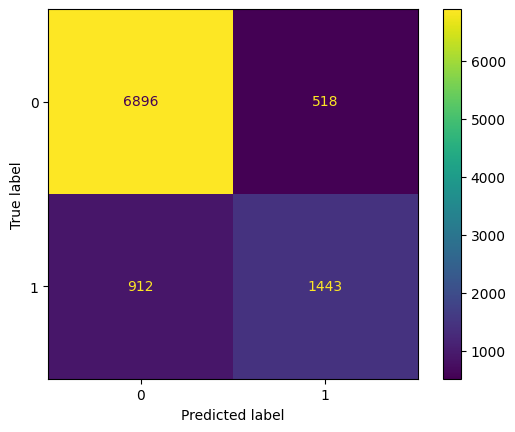

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, rf_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred
)

In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.88      0.93      0.91      7414
           1       0.74      0.61      0.67      2355

    accuracy                           0.85      9769
   macro avg       0.81      0.77      0.79      9769
weighted avg       0.85      0.85      0.85      9769



In [41]:
from sklearn.metrics import roc_auc_score

rf_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {rf_auc:.4f}")

ROC-AUC: 0.8999


In [42]:
import joblib

joblib.dump(
    rf_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/adult_random_forest.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/adult_random_forest.pkl']

In [43]:
rf_results = {
    "Model": "Random Forest",
    "Accuracy": round(rf_accuracy, 4),
    "Precision": round(rf_precision, 4),
    "Recall": round(rf_recall, 4),
    "F1 Score": round(rf_f1, 4),
    "ROC-AUC": round(rf_auc, 4)
}

##XGBoost

In [44]:
!pip install xgboost

In [45]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [46]:
xgb_pred = xgb_model.predict(X_test)

In [47]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)

print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")

Accuracy : 0.8729
Precision: 0.7773
Recall   : 0.6624
F1 Score : 0.7153


[[6967  447]
 [ 795 1560]]


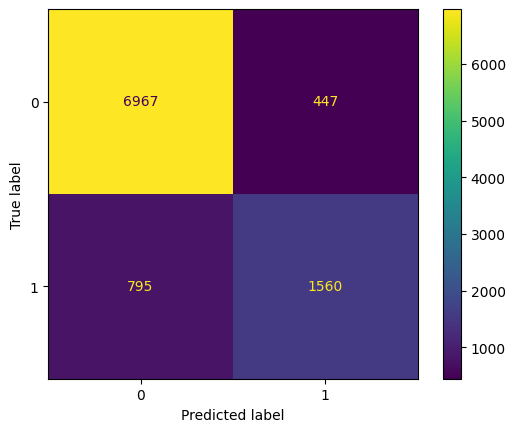

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, xgb_pred)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred
)

In [49]:
from sklearn.metrics import classification_report

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.90      0.94      0.92      7414
           1       0.78      0.66      0.72      2355

    accuracy                           0.87      9769
   macro avg       0.84      0.80      0.82      9769
weighted avg       0.87      0.87      0.87      9769



In [50]:
from sklearn.metrics import roc_auc_score

xgb_auc = roc_auc_score(
    y_test,
    xgb_model.predict_proba(X_test)[:, 1]
)

print(f"ROC-AUC: {xgb_auc:.4f}")

ROC-AUC: 0.9243


In [51]:
import joblib

joblib.dump(
    xgb_model,
    "/content/drive/MyDrive/XAI-Stability-Bench/models/adult_xgboost.pkl"
)

['/content/drive/MyDrive/XAI-Stability-Bench/models/adult_xgboost.pkl']

In [52]:
xgb_results = {
    "Model": "XGBoost",
    "Accuracy": round(xgb_accuracy, 4),
    "Precision": round(xgb_precision, 4),
    "Recall": round(xgb_recall, 4),
    "F1 Score": round(xgb_f1, 4),
    "ROC-AUC": round(xgb_auc, 4)
}

##Final Table

In [53]:
import pandas as pd

results_df = pd.DataFrame([
    lr_results,
    dt_results,
    rf_results,
    xgb_results
])

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8489,0.7390,0.5771,0.6481,0.9035
1,Decision Tree,0.8148,0.6141,0.6238,0.6189,0.7496
2,Random Forest,0.8536,0.7358,0.6127,0.6687,0.8999
3,XGBoost,0.8729,0.7773,0.6624,0.7153,0.9243


In [54]:
results_df.to_csv(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/adult_model_comparison.csv",
    index=False
)

In [55]:
import os

os.path.exists(
    "/content/drive/MyDrive/XAI-Stability-Bench/results/adult_model_comparison.csv"
)

True